# PCA

Principal Component Analysis (PCA) is an unsupervised machine learning technique used to reduce the number of features in a large dataset while keeping the most important information

# For more info please click the link below

https://docs.google.com/document/d/15GvkE_8Pm2vOtudsMwNRyQEdEydOwtmp5Uamv0HHUFY/edit?usp=sharing

# notes and interview and Q and answer

https://docs.google.com/document/d/10PR5YHG7Ess7sLSHVdQy8lKlSpRWedwBG5606V-91gU/edit?usp=sharing

# Coding

# Import libraries 

In [2]:
from sklearn.datasets import load_wine
import numpy as np                       # Numerical calculations
import pandas as pd                      # Data manipulation
import matplotlib.pyplot as plt          # Visualization

from sklearn.datasets import load_wine   # Wine dataset
from sklearn.preprocessing import StandardScaler  # Standardizes features before PCA
from sklearn.decomposition import PCA    # PCA algorithm


# Load and explore the dataset 

In [5]:
wine = load_wine()                       # Load the built-in Wine dataset

X = wine.data                             # 13 numerical features used by PCA
y = wine.target                           # Class labels; PCA itself does not use these labels

print("X shape:", X.shape)                # Shows number of samples and features
print("y shape:", y.shape)                # Shows number of target labels
print("Features:", wine.feature_names)    # Shows the original feature names

X shape: (178, 13)
y shape: (178,)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


# look at the data 

In [7]:
# Look at the data
df = pd.DataFrame(
    X,
    columns=wine.feature_names              # Use Wine feature names as DataFrame columns
)

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


`Why scaling is important before PCA `
`This is very important `
`PCA is based on variance`


# Standardize the data 


In [9]:
scaler = StandardScaler()                 # Creates a standardization object

X_scaled = scaler.fit_transform(
    X                                      # Calculate mean/std from X and transform every feature
)

print("Original shape:", X.shape)          # 13 original features
print("Scaled shape:", X_scaled.shape)     # Still 13 features; scaling does not reduce dimensions

Original shape: (178, 13)
Scaled shape: (178, 13)


# Create PCA

In [10]:
# First let's let PCA calculate all components 
pca = PCA()                               # Calculate all possible principal components

X_pca = pca.fit_transform(
    X_scaled                              # PCA learns directions of maximum variance from scaled data
)

print("Original shape:", X_scaled.shape)   # 178 × 13
print("PCA shape:", X_pca.shape)           # 178 × 13

Original shape: (178, 13)
PCA shape: (178, 13)


# Understand explained variance 
`THis is one of the most important concepts in PCA `

In [13]:
explained_variance = pca.explained_variance_ratio_

print(explained_variance)

# if the output -
# PC1 → 36%
# PC2 → 19%
# PC3 → 11%
# PC4 → 7%
#... 

# This means PC1 contains the largest amount of variance/information, PC2 the second largest, and so on.

[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]


# Cumulative explained variance 

In [14]:
cumulative_variance = np.cumsum(
    explained_variance                    # Add explained variance component by component
)

print(cumulative_variance)

[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


# Visualize explained variance 



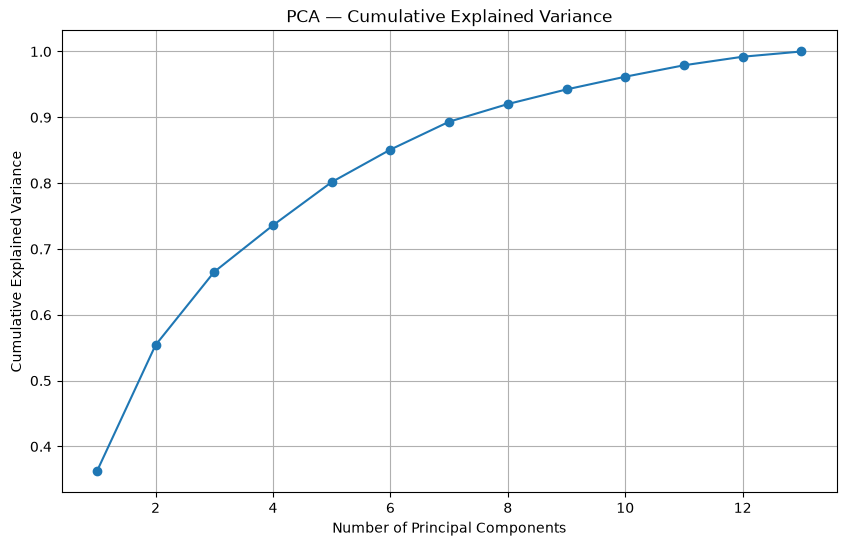

In [16]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),  # Component numbers: 1, 2, 3, ...
    cumulative_variance,                     # Cumulative explained variance
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance")

plt.grid()
plt.show()

# How many components should we keep ?
`instead of gussing, we can ask PCA to retain, for example, 95% of the variance.`

In [17]:
pca_95 = PCA(
    n_components=0.95                     # Automatically select components retaining at least 95% variance
)

X_pca_95 = pca_95.fit_transform(
    X_scaled                              # Apply PCA to standardized data
)

print("Original dimensions:", X_scaled.shape[1])       # 13 original features
print("Reduced dimensions:", X_pca_95.shape[1])        # Number of components needed for 95% variance
print("Explained variance:", pca_95.explained_variance_ratio_.sum())  # Total retained variance

Original dimensions: 13
Reduced dimensions: 10
Explained variance: 0.9616971684450644


# PCA with exactly 2 components 

`The 2 components are extremely useful because we can visualize them . `


In [19]:
pca_2 = PCA(
    n_components=2                         # Reduce 13 dimensions to exactly 2 principal components
)

X_pca_2 = pca_2.fit_transform(
    X_scaled                              # Learn PCA directions and transform the data
)

print("Original shape:", X_scaled.shape)   # (178, 13)
print("Reduced shape:", X_pca_2.shape)     # (178, 2)

Original shape: (178, 13)
Reduced shape: (178, 2)


# Understnad PC1 and PC2



In [20]:
print("PC1 variance:", pca_2.explained_variance_ratio_[0])
print("PC2 variance:", pca_2.explained_variance_ratio_[1])

print(
    "Total variance retained:",
    pca_2.explained_variance_ratio_.sum()
)

PC1 variance: 0.36198848099926345
PC2 variance: 0.1920749025700894
Total variance retained: 0.5540633835693529


# Visualize PCA result 

`PCA doesn't know about y`

`we are using y here only to visualize distingguish the tree wine classes.`

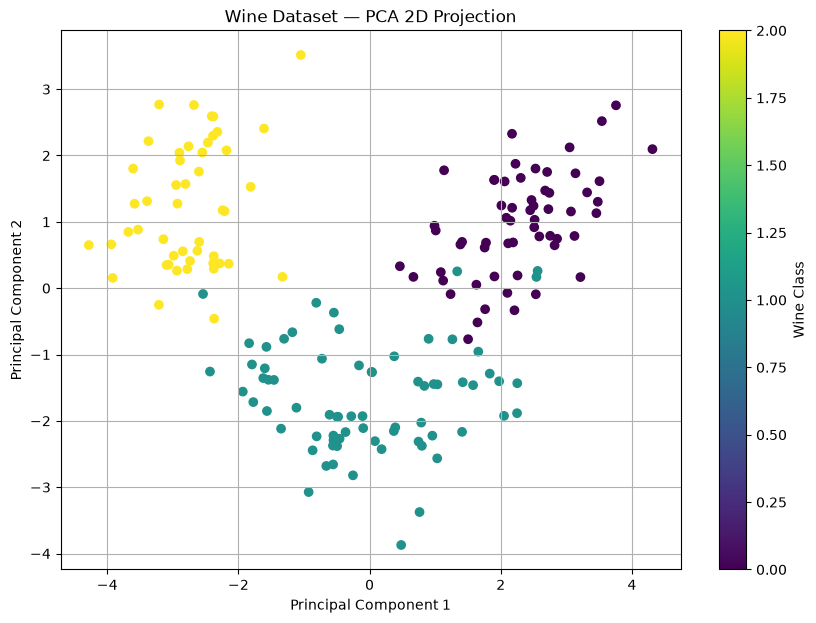

In [21]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca_2[:, 0],                         # First principal component
    X_pca_2[:, 1],                         # Second principal component
    c=y                                    # Color points according to Wine class for visualization only
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset — PCA 2D Projection")

plt.colorbar(scatter, label="Wine Class")
plt.grid()
plt.show()